# 数据安全与隐私 · 结果加密、访问控制与审计

QuantumBridge / 量子安全 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 经典安全工程教学流程，不是量子加密、同态计算、MPC、身份服务或完整生产权限平台。密钥管理、可信锚持久化及部署安全需另行设计。

## 1. 原理与计算对象

使用已安装 cryptography 的 AES-256-GCM 加密合成量子任务结果，同时认证未加密的任务上下文 AAD。每次执行新生成密钥与 12 字节 nonce，不复用同一密钥/nonce 对。
修改密文或 AAD 时，库应抛出 InvalidTag。角色表采用默认拒绝，viewer 只读、operator 可准备本地任务；角色输入不是已经实现了身份认证。

审计记录对规范 JSON、索引和前一条标签计算 HMAC-SHA256。验证端另存可信链长和尾标签，检查篡改及截断。没有外部可信锚时，单纯哈希链不能保证管理员无法截断历史；本例明确携带验证锚，并不冒充生产审计系统。

## 2. 实现步骤

1. 创建纯合成任务结果和上下文，不接触患者、金融或账户私密数据。
2. 执行 AES-GCM 加密/解密，验证正常往返。
3. 分别篡改密文和上下文，确认认证失败。
4. 运行默认拒绝角色表并记录决策。
5. 生成带认证的审计链，用可信长度与尾标签检出改动及截断。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
import copy
import hashlib
import hmac
import json
import os
from pathlib import Path
import shutil
import subprocess
import tempfile
import numpy as np
from quantumbridge.core import Circuit
from quantumbridge.devices import StatevectorDevice
from quantumbridge.finance.kernels import labels
from quantumbridge.applications.common import ApplicationCase

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def audit_record(payload, index, previous, key):
    record = {"index": index, "previous": previous, "payload": payload}
    canonical = json.dumps(record, sort_keys=True, separators=(",", ":")).encode()
    return {**record, "tag": hmac.new(key, canonical, hashlib.sha256).hexdigest()}


def verify_audit(records, key, expected_length, expected_tail):
    if len(records) != expected_length:
        return False
    previous = "0" * 64
    for index, record in enumerate(records):
        expected = audit_record(record["payload"], index, previous, key)
        if (
            record["index"] != index
            or record["previous"] != previous
            or not hmac.compare_digest(expected["tag"], record["tag"])
        ):
            return False
        previous = record["tag"]
    return hmac.compare_digest(previous, expected_tail)


def privacy_case():
    from cryptography.exceptions import InvalidTag
    from cryptography.hazmat.primitives.ciphers.aead import AESGCM

    cipher = AESGCM(AESGCM.generate_key(bit_length=256))
    nonce, aad = os.urandom(12), b"QuantumBridge/synthetic-job/local-only"
    message = json.dumps(
        {"model": "synthetic-H2", "counts": {"00": 520, "11": 504}}, sort_keys=True
    ).encode()
    encrypted = cipher.encrypt(nonce, message, aad)
    roundtrip = cipher.decrypt(nonce, encrypted, aad) == message
    attempts = [
        ("ciphertext", bytes([encrypted[0] ^ 1]) + encrypted[1:], aad),
        ("metadata", encrypted, aad + b"-altered"),
    ]
    checks = []
    for name, altered, metadata in attempts:
        try:
            cipher.decrypt(nonce, altered, metadata)
        except InvalidTag:
            checks.append({"attack": name, "rejected": True})
        else:
            checks.append({"attack": name, "rejected": False})
    permissions = {"viewer": {"read"}, "operator": {"read", "prepare_local"}}
    access = [
        {
            "role": role,
            "action": action,
            "allowed": action in permissions.get(role, set()),
        }
        for role, action in (
            ("viewer", "read"),
            ("viewer", "prepare_local"),
            ("operator", "prepare_local"),
            ("unknown", "read"),
        )
    ]
    key, records, previous = os.urandom(32), [], "0" * 64
    for index, payload in enumerate(access):
        record = audit_record(payload, index, previous, key)
        records.append(record)
        previous = record["tag"]
    changed = copy.deepcopy(records)
    changed[1]["payload"]["allowed"] = True
    good = verify_audit(records, key, len(records), previous)
    tampered = not verify_audit(changed, key, len(records), previous)
    truncated = not verify_audit(records[:-1], key, len(records), previous)
    return ApplicationCase(
        "privacy",
        "security",
        "Authenticated result encryption, access decisions and anchored audit",
        {
            "encryption": "cryptography AES-256-GCM",
            "nonce_bytes": 12,
            "nonce_policy": "fresh OS randomness with fresh key per example",
            "data": "synthetic quantum-job counts only",
            "audit": "HMAC-SHA256 chain; expected length and tail retained by verifier",
        },
        {
            "access_decisions": access,
            "integrity_checks": checks,
            "public_audit_records": records,
            "chart_rows": [
                {"label": "Round trip", "value": int(roundtrip)},
                {"label": "Ciphertext rejected", "value": int(checks[0]["rejected"])},
                {"label": "Metadata rejected", "value": int(checks[1]["rejected"])},
                {"label": "Audit tamper rejected", "value": int(tampered)},
            ],
            "chart_units": "Check passed (1/0)",
            "chart_title": "Actual classical cryptography checks",
        },
        {"tag_overhead_bytes": 16},
        {},
        outputs={
            "roundtrip_ok": roundtrip,
            "ciphertext_bytes": len(encrypted),
            "plaintext_bytes": len(message),
            "altered_ciphertext_rejected": checks[0]["rejected"],
            "altered_aad_rejected": checks[1]["rejected"],
            "valid_audit_accepted": good,
            "audit_tamper_rejected": tampered,
            "truncation_rejected_with_anchor": truncated,
            "secret_material_exported": False,
            "identity_authentication": "not implemented; roles are explicit teaching inputs",
            "homomorphic_or_mpc_implemented": False,
        },
    )


In [3]:
case = privacy_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

role,action,allowed
viewer,read,True
viewer,prepare_local,False
operator,prepare_local,True
unknown,read,False


attack,rejected
ciphertext,True
metadata,True


index,previous,payload,tag
0,0000000000000000000000000000000000000000000000000000000000000000,"{""role"": ""viewer"", ""action"": ""read"", ""allowed"": true}",44d486605437be30b1f0315f65533b01494257a03d70678fbf6ecbbb6970bd57
1,44d486605437be30b1f0315f65533b01494257a03d70678fbf6ecbbb6970bd57,"{""role"": ""viewer"", ""action"": ""prepare_local"", ""allowed"": false}",d5e62a80d05c8b496a4c41820a587a01e1447431cdead7f1cd6fde1a335278b5
2,d5e62a80d05c8b496a4c41820a587a01e1447431cdead7f1cd6fde1a335278b5,"{""role"": ""operator"", ""action"": ""prepare_local"", ""allowed"": true}",23a6137317c77095909d1b8ab19d64f842742103a6b0db95175c9bfa0a210c71
3,23a6137317c77095909d1b8ab19d64f842742103a6b0db95175c9bfa0a210c71,"{""role"": ""unknown"", ""action"": ""read"", ""allowed"": false}",182fa649792e9d9b04ca3239954f314830cb5d021219c52abf4278cf06dba556


label,value
Round trip,1
Ciphertext rejected,1
Metadata rejected,1
Audit tamper rejected,1


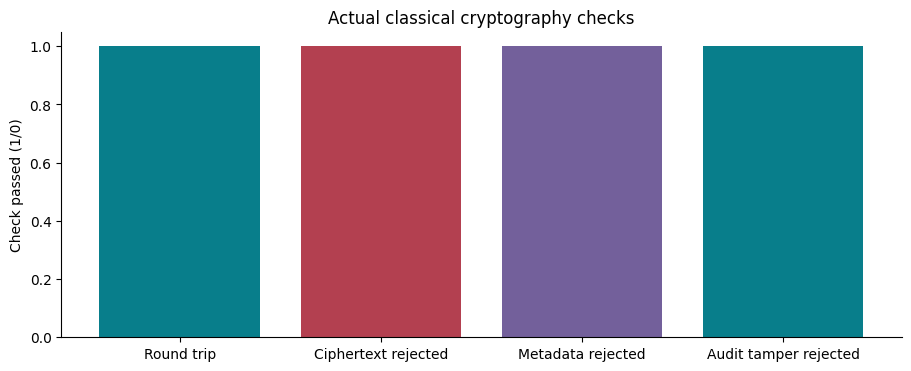

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')

Classical cryptography / security workflow: no quantum circuit.


## 8. 结果解释、复做与非目标

roundtrip_ok、altered_ciphertext_rejected、altered_aad_rejected、audit_tamper_rejected 均应为 true。密文长度比明文多 16 字节认证标签；密钥不写入 Notebook 或证据。

经典安全工程教学流程，不是量子加密、同态计算、MPC、身份服务或完整生产权限平台。密钥管理、可信锚持久化及部署安全需另行设计。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/security/05_privacy_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 05_privacy_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [cryptography 46.0.7 AEAD 接口与 nonce 约束](https://cryptography.io/en/46.0.7/hazmat/primitives/aead/)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。